# Titanic Survival Prediction — Full Workflow Template

**Goal**: Walk through the full pipeline — data cleaning, feature engineering, modeling,
model evaluation, and visualization. Each step has `# TODO` notes and thinking questions
to help you understand *why* you're doing each step, so you can explain it clearly in an interview
instead of just saying "I ran a model."

**Dataset**: Kaggle "Titanic - Machine Learning from Disaster"
Download link: https://www.kaggle.com/competitions/titanic/data
Download `train.csv` and put it in the same folder as this notebook.

**Suggested time**: 1-2 days to finish the whole pipeline. If you want to polish it, spend
extra time on the "Model Evaluation" section — that's the part this internship's job description
cares about most.


## 1. Setup and Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score, classification_report
)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

df = pd.read_csv("train.csv")
df.head()


Matplotlib is building the font cache; this may take a moment.


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Explore the Data (EDA)

First, get a feel for the data: how many rows, which columns have missing values,
and whether the target variable (`Survived`) is balanced.

**Thinking question**: if `Survived` were heavily imbalanced (say 80% did not survive,
20% did), how would that affect how you evaluate your model later?
(Hint: this is why we should not rely on accuracy alone — more on this in Section 6.)


In [2]:
df.info()
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nTarget variable distribution:")
print(df["Survived"].value_counts(normalize=True))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing values per column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarke

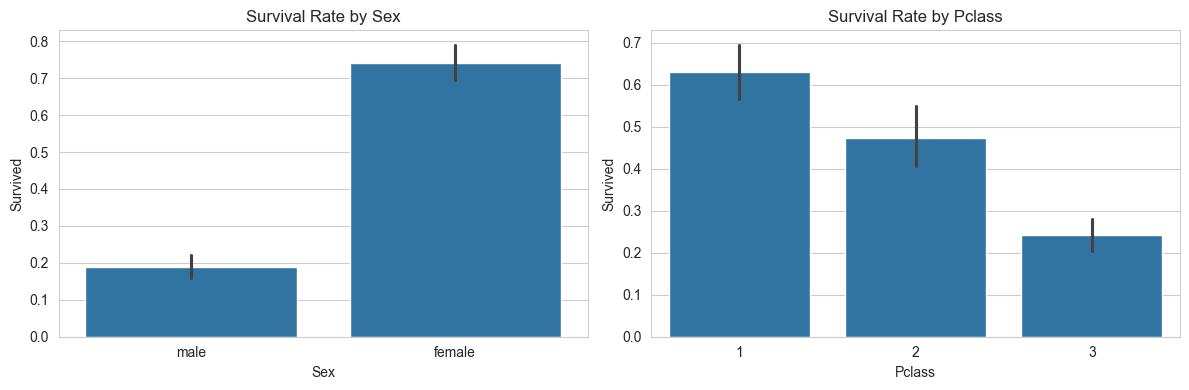

In [3]:
# Quick visualization: survival rate by sex and by passenger class
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=df, x="Sex", y="Survived", ax=axes[0])
axes[0].set_title("Survival Rate by Sex")
sns.barplot(data=df, x="Pclass", y="Survived", ax=axes[1])
axes[1].set_title("Survival Rate by Pclass")
plt.tight_layout()
plt.show()


## 3. Data Cleaning (Handling Missing Values)

`Age` has quite a few missing values, `Cabin` is missing for most rows, and `Embarked`
is missing for only a couple of rows.

**This is the part interviewers most often ask you to justify.** There's no single
"correct" answer, but you should be able to explain *why* you chose your approach:
- Fill `Age` with the overall median? Simple, but ignores that age naturally differs
  across passenger class and sex.
- Fill `Age` with the median *within each group* (e.g. by Pclass + Sex)? More precise,
  but you should be able to explain why that grouping makes sense.
- `Cabin` is missing for most rows — should you drop the column entirely, or turn it
  into a new feature like "did we have a cabin record for this passenger or not"?

The code below fills `Age` using group medians. Try swapping it for a simple overall
median and compare how much the final model's performance changes — that comparison
itself is a great story to tell about a trade-off you made and tested.


In [4]:
# Fill Age using the median within each Pclass + Sex group
df["Age"] = df.groupby(["Pclass", "Sex"])["Age"].transform(lambda x: x.fillna(x.median()))

# Embarked has very few missing values, so just fill with the most common value
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Cabin is missing for most rows — instead of dropping the info entirely,
# turn it into a binary feature: "did we have a cabin record for this passenger?"
df["HasCabin"] = df["Cabin"].notnull().astype(int)

# Confirm missing values are handled
df[["Age", "Embarked", "Cabin", "HasCabin"]].isnull().sum()


Age           0
Embarked      0
Cabin       687
HasCabin      0
dtype: int64

## 4. Feature Engineering

Extract the title (Mr/Mrs/Miss/Master, etc.) from the `Name` column — a person's title
often carries information about age group and social status, and can be more predictive
than the raw name itself. This is a good example of "I understood the data, not just
copied a template."

Also combine `SibSp` (siblings/spouses aboard) and `Parch` (parents/children aboard)
into a single `FamilySize` feature. Think about it: how might family size affect a
person's priority or behavior when trying to escape?


In [5]:
# Extract title from name
df["Title"] = df["Name"].str.extract(r",\s*([^\.]*)\.")
# Group rare titles together so the category isn't too sparse
title_counts = df["Title"].value_counts()
rare_titles = title_counts[title_counts < 10].index
df["Title"] = df["Title"].replace(rare_titles, "Rare")
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})

# Family size
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

df[["Name", "Title", "SibSp", "Parch", "FamilySize", "IsAlone"]].head()


,Name,Title,SibSp,Parch,FamilySize,IsAlone
0,"Braund, Mr. Owen Harris",Mr,1,0,2,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,1,0,2,0
2,"Heikkinen, Miss. Laina",Miss,0,0,1,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,1,0,2,0
4,"Allen, Mr. William Henry",Mr,0,0,1,1


In [6]:
# Encode categorical variables
df_model = pd.get_dummies(
    df[["Survived", "Pclass", "Sex", "Age", "Fare", "Embarked",
        "Title", "FamilySize", "IsAlone", "HasCabin"]],
    columns=["Pclass", "Sex", "Embarked", "Title"],
    drop_first=True
)
df_model.head()


,Survived,Age,Fare,FamilySize,IsAlone,HasCabin,Pclass_2,Pclass_3,Sex_male,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,0,22.0,7.2500,2,0,0,False,True,True,False,True,False,True,False,False
1,1,38.0,71.2833,2,0,1,False,False,False,False,False,False,False,True,False
2,1,26.0,7.9250,1,1,0,False,True,False,False,True,True,False,False,False
3,1,35.0,53.1000,2,0,1,False,False,False,False,True,False,False,True,False
4,0,35.0,8.0500,1,1,0,False,True,True,False,True,False,True,False,False


## 5. Train/Test Split + Modeling (Baseline first, then compare)

Start with a simple logistic regression as a baseline, then compare it against a
random forest.

**Why a baseline matters**: if an interviewer asks "how do you know the random forest
is actually better," you need a benchmark number to compare against — not just a
feeling that "random forest is usually better."


In [7]:
X = df_model.drop(columns=["Survived"])
y = df_model["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Baseline: Logistic Regression
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_scaled, y_train)
y_pred_log = log_reg.predict(X_test_scaled)

# Comparison model: Random Forest
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)  # tree models don't need scaling
y_pred_rf = rf.predict(X_test)


## 6. Model Evaluation (the most important step — this is what the job description means by "assess model performance")

**Key point: don't just look at accuracy.**

Think about it: in the Titanic scenario,
- Predicting "survived" when the passenger actually died (False Positive)
- Predicting "died" when the passenger actually survived (False Negative)

Which mistake matters more here? This kind of question matters even more in real
business settings (like credit risk or medical diagnosis) — use Titanic to practice
this way of thinking.


In [8]:
def evaluate_model(y_true, y_pred, model_name):
    print(f"===== {model_name} =====")
    print(f"Accuracy:  {accuracy_score(y_true, y_pred):.3f}")
    print(f"Precision: {precision_score(y_true, y_pred):.3f}")
    print(f"Recall:    {recall_score(y_true, y_pred):.3f}")
    print(f"F1 Score:  {f1_score(y_true, y_pred):.3f}")
    print()
    print(classification_report(y_true, y_pred))

evaluate_model(y_test, y_pred_log, "Logistic Regression")
evaluate_model(y_test, y_pred_rf, "Random Forest")


===== Logistic Regression =====
Accuracy:  0.838
Precision: 0.803
Recall:    0.768
F1 Score:  0.785

              precision    recall  f1-score   support

           0       0.86      0.88      0.87       110
           1       0.80      0.77      0.79        69

    accuracy                           0.84       179
   macro avg       0.83      0.82      0.83       179
weighted avg       0.84      0.84      0.84       179

===== Random Forest =====
Accuracy:  0.793
Precision: 0.750
Recall:    0.696
F1 Score:  0.722

              precision    recall  f1-score   support

           0       0.82      0.85      0.84       110
           1       0.75      0.70      0.72        69

    accuracy                           0.79       179
   macro avg       0.78      0.78      0.78       179
weighted avg       0.79      0.79      0.79       179



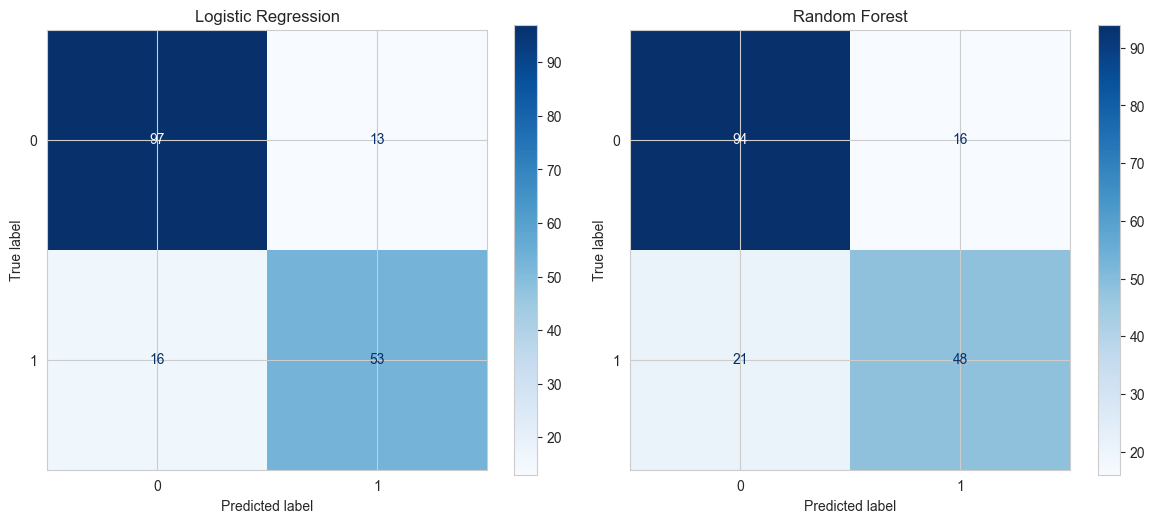

In [9]:
# Confusion matrix comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_log, ax=axes[0], cmap="Blues")
axes[0].set_title("Logistic Regression")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, ax=axes[1], cmap="Blues")
axes[1].set_title("Random Forest")
plt.tight_layout()
plt.show()


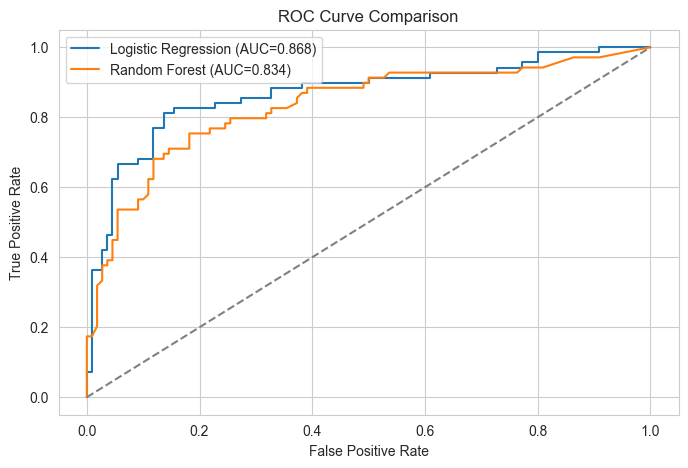

In [10]:
# ROC curve comparison
y_prob_log = log_reg.predict_proba(X_test_scaled)[:, 1]
y_prob_rf = rf.predict_proba(X_test)[:, 1]

fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.plot(fpr_log, tpr_log, label=f"Logistic Regression (AUC={roc_auc_score(y_test, y_prob_log):.3f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC={roc_auc_score(y_test, y_prob_rf):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()


## 7. Feature Importance + Turning Results Into a Visual Insight

This step matches the job description's "identify and visualize key insights" requirement:
don't just report a number — translate the result into a plain-language takeaway.


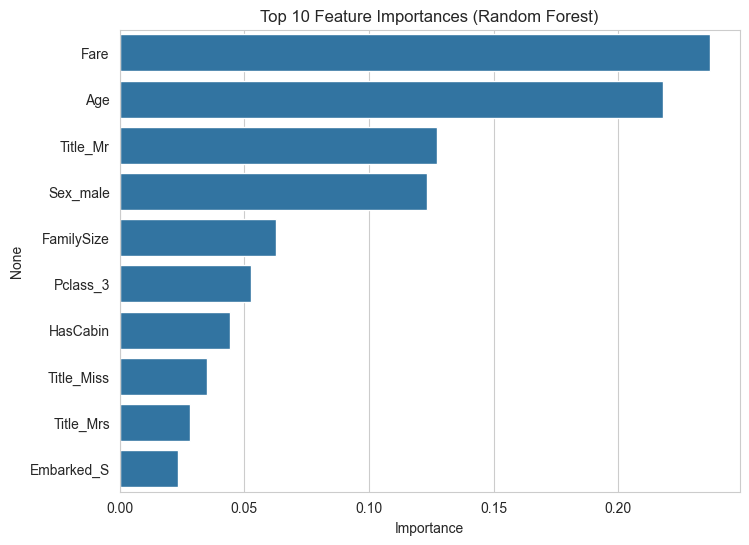

Fare          0.236710
Age           0.217684
Title_Mr      0.127230
Sex_male      0.123310
FamilySize    0.062588
Pclass_3      0.052625
HasCabin      0.044368
Title_Miss    0.034899
Title_Mrs     0.028294
Embarked_S    0.023261
dtype: float64


In [11]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
sns.barplot(x=importances.values[:10], y=importances.index[:10])
plt.title("Top 10 Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.show()

print(importances.head(10))


## 8. Write Your Conclusions (this becomes your resume/interview material)

**TODO: fill these in based on your actual results.** A little polishing turns these
sentences directly into your resume project description:

1. Dataset size, missing-value situation, and how/why you handled it: ___
2. Key metric comparison — baseline (logistic regression) vs. comparison model (random forest): ___
3. Which feature mattered most, whether that matches your intuition, and what it implies: ___
4. If you had more time, what would you try next (tuning, cross-validation, XGBoost,
   handling class imbalance)? ___

---

### Bonus ideas if you have extra time
- Add **k-fold cross-validation** (`cross_val_score`) to make your results more robust —
  this is also a common interview topic
- Try handling **class imbalance** (Titanic isn't too imbalanced, but it's good practice
  with `class_weight="balanced"` or SMOTE)
- Run a simple hyperparameter search with `GridSearchCV`, and be ready to explain
  what you searched over and why
